# Project 8 — Skill or exposure? Performance attribution of Fidelity Contrafund (FCNTX)
Part A: returns-based analysis, October 2011 – September 2026 (factor regressions end August 2026, the
latest month in the Kenneth French library). Part B: holdings-based Brinson-Fachler attribution for
calendar year 2025 from Form N-PORT holdings, benchmark IVV (iShares Core S&P 500 ETF).

In [1]:
import json
import re
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path[:0] = [str(ROOT), str(ROOT.parent), str(ROOT.parent / "07-factor-premia")]

import numpy as np
import pandas as pd
import statsmodels.api as sm

from common import data as D
from common.plotting import PALETTE, setup, source
from src import brinson as BR

plt = setup()
DATA, FIG = ROOT / "data", ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.options.display.float_format = "{:.4f}".format
SRC_A = "Source: yfinance (FCNTX, IVV), Kenneth French Data Library; author's calculations."

## Part A — returns-based

In [2]:
px = D.prices(["FCNTX", "IVV"], "2011-09-01", "2026-10-01", DATA / "fund_prices_daily.csv")
R = D.monthly_returns(px).loc["2011-10":"2026-09"]
ff = D.french("F-F_Research_Data_5_Factors_2x3", DATA / "ff5_monthly.csv")
mom = D.french("F-F_Momentum_Factor", DATA / "ff_momentum_monthly.csv")
F6 = ff.join(mom)
F6.columns = [c.strip() for c in F6.columns]
ex = R.sub(F6["RF"], axis=0).dropna()
print("Returns:", R.index[0].date(), "-", R.index[-1].date(), len(R), "| regressions:", ex.index[0].date(), "-", ex.index[-1].date(), len(ex))


def reg(y, cols):
    d = pd.concat([y, F6[cols]], axis=1).dropna()
    return sm.OLS(d.iloc[:, 0], sm.add_constant(d.iloc[:, 1:])).fit(cov_type="HAC", cov_kwds={"maxlags": 3})


MODELS = {"CAPM": ["Mkt-RF"], "FF3": ["Mkt-RF", "SMB", "HML"], "FF5 + Mom": ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]}
rows = {}
for name, cols in MODELS.items():
    m = reg(ex["FCNTX"], cols)
    row = {"Alpha (ann.)": m.params["const"] * 12, "t(alpha)": m.tvalues["const"], "R2": m.rsquared, "N": int(m.nobs)}
    for c in cols:
        row[c] = m.params[c]; row[f"t({c})"] = m.tvalues[c]
    rows[name] = row
REG = pd.DataFrame(rows).T
# IVV on the same models, as a check on the factor data (should show ~0 alpha, beta ~1)
ivv6 = reg(ex["IVV"], MODELS["FF5 + Mom"])
print(f"IVV check: alpha {ivv6.params['const'] * 12:.2%} (t {ivv6.tvalues['const']:.2f}), market beta {ivv6.params['Mkt-RF']:.3f}")
REG

Returns: 2011-10-31 - 2026-09-30 180 | regressions: 2011-10-31 - 2026-08-31 179
IVV check: alpha -0.12% (t -0.59), market beta 0.988


/tmp/ipykernel_7412/2301878781.py:12: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  d = pd.concat([y, F6[cols]], axis=1).dropna()
/tmp/ipykernel_7412/2301878781.py:12: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  d = pd.concat([y, F6[cols]], axis=1).dropna()
/tmp/ipykernel_7412/2301878781.py:12: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence

,Alpha (ann.),t(alpha),R2,N,Mkt-RF,t(Mkt-RF),SMB,t(SMB),HML,t(HML),RMW,t(RMW),CMA,t(CMA),Mom,t(Mom)
CAPM,0.0165,1.1062,0.8835,179.0000,0.9652,30.9036,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FF3,0.0116,1.1784,0.9303,179.0000,0.9902,42.8996,-0.1413,-3.3303,-0.2221,-7.9756,NaN,NaN,NaN,NaN,NaN,NaN
FF5 + Mom,0.0073,0.7783,0.9379,179.0000,0.9996,41.7445,-0.1181,-2.5460,-0.1391,-3.8558,0.0314,0.6313,-0.1438,-2.4612,0.1007,3.5824


/tmp/ipykernel_7412/665422774.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  d = pd.concat([ex["FCNTX"], F6[cols6]], axis=1).dropna()


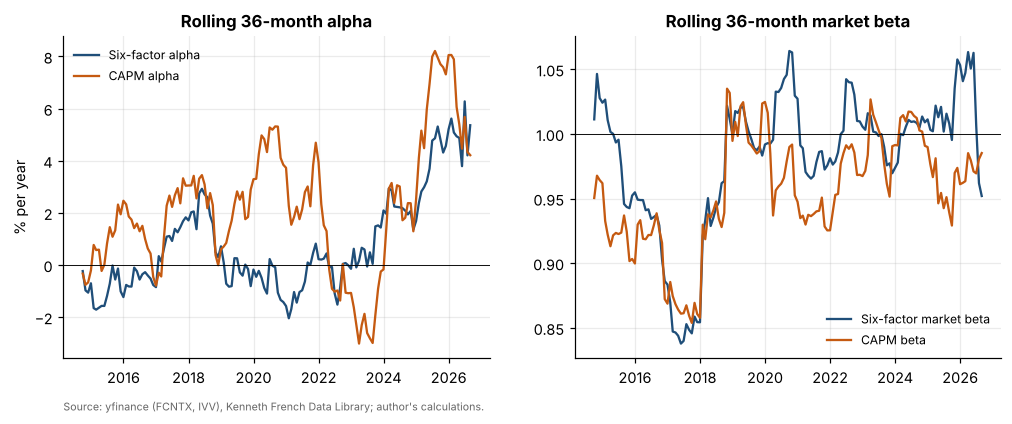

In [3]:
cols6 = MODELS["FF5 + Mom"]
d = pd.concat([ex["FCNTX"], F6[cols6]], axis=1).dropna()
roll = {}
for i in range(36, len(d) + 1):
    s = d.iloc[i - 36:i]
    m = sm.OLS(s.iloc[:, 0], sm.add_constant(s.iloc[:, 1:])).fit()
    mc = sm.OLS(s.iloc[:, 0], sm.add_constant(s[["Mkt-RF"]])).fit()
    roll[s.index[-1]] = {"Alpha 6F (ann.)": m.params["const"] * 12, "Beta 6F": m.params["Mkt-RF"],
                         "Alpha CAPM (ann.)": mc.params["const"] * 12, "Beta CAPM": mc.params["Mkt-RF"]}
ROLL = pd.DataFrame(roll).T
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ROLL.index, ROLL["Alpha 6F (ann.)"] * 100, color=PALETTE[0], label="Six-factor alpha")
ax[0].plot(ROLL.index, ROLL["Alpha CAPM (ann.)"] * 100, color=PALETTE[1], label="CAPM alpha")
ax[0].axhline(0, color="black", lw=0.6); ax[0].set_ylabel("% per year"); ax[0].legend(fontsize=8)
ax[0].set_title("Rolling 36-month alpha")
ax[1].plot(ROLL.index, ROLL["Beta 6F"], color=PALETTE[0], label="Six-factor market beta")
ax[1].plot(ROLL.index, ROLL["Beta CAPM"], color=PALETTE[1], label="CAPM beta")
ax[1].axhline(1, color="black", lw=0.6); ax[1].legend(fontsize=8); ax[1].set_title("Rolling 36-month market beta")
source(ax[0], SRC_A)
fig.savefig(FIG / "fig_rolling_alpha_beta.png"); plt.show()

In [4]:
a = R["FCNTX"] - R["IVV"]
te = a.std() * np.sqrt(12)
ann = lambda r: (1 + r).prod() ** (12 / len(r)) - 1
up, dn = R["IVV"] > 0, R["IVV"] < 0
REL = pd.Series({"FCNTX ann. return": ann(R["FCNTX"]), "IVV ann. return": ann(R["IVV"]),
                 "Excess return (ann., geometric)": ann(R["FCNTX"]) - ann(R["IVV"]),
                 "Tracking error": te, "Information ratio": a.mean() * 12 / te,
                 "Up-capture": ann(R.loc[up, "FCNTX"]) / ann(R.loc[up, "IVV"]),
                 "Down-capture": ann(R.loc[dn, "FCNTX"]) / ann(R.loc[dn, "IVV"]),
                 "Up months": int(up.sum()), "Down months": int(dn.sum())})
REL

FCNTX ann. return                   0.1703
IVV ann. return                     0.1557
Excess return (ann., geometric)     0.0146
Tracking error                      0.0520
Information ratio                   0.2701
Up-capture                          1.0245
Down-capture                        0.9639
Up months                         126.0000
Down months                        53.0000
dtype: float64

## Part B — holdings-based Brinson-Fachler attribution, 2025
Each quarter the starting N-PORT holdings are held unchanged (buy-and-hold). Listed securities are valued
with yfinance total-return prices converted to USD; holdings without a market price (private companies)
use the fund's own fair values from consecutive N-PORT filings (value per unit). Cash and money market
funds earn the 3-month T-bill. Sectors are yfinance sector fields, applied identically to both portfolios.

In [5]:
Q = ["2024-12-31", "2025-03-31", "2025-06-30", "2025-09-30", "2025-12-31"]
meta = json.load(open(DATA / "nport" / "filings.json"))
sec = pd.read_csv(DATA / "security_master.csv", index_col=0)
P = pd.read_csv(DATA / "quarter_end_prices_usd.csv", index_col=0)
sector = pd.read_csv(DATA / "sectors.csv", index_col=0)["sector"].fillna("Unclassified")
tb = D.tbill_monthly(DATA / "fred_TB3MS.csv")


def nport(label, d):
    x = pd.read_csv(DATA / "nport" / f"{label}_{d}.csv")
    x["key"] = x["isin"].fillna(x["name"].str.upper() + " | " + x["title"].fillna("").str.upper())
    return x


def quarter_returns(label, q0, q1):
    """Per-holding return for the quarter q0 -> q1 and its source."""
    h0 = nport(label, q0)
    nav = float(meta[label][q0]["net_assets"]) if q0 in meta[label] else h0["value_usd"].sum()
    h0["w"] = h0["value_usd"] / nav
    months = pd.period_range(pd.Period(q0, "M") + 1, pd.Period(q1, "M"), freq="M")
    rq = float(np.prod([1 + tb.loc[str(m)].iloc[0] for m in months]) - 1)
    nxt = nport(label, q1) if (DATA / "nport" / f"{label}_{q1}.csv").exists() else None
    ret, src = [], []
    for _, r in h0.iterrows():
        if r["asset_cat"] in ("STIV",) or str(r["title"]).upper().find("CASH") >= 0:
            ret.append(rq); src.append("T-bill (cash)"); continue
        if r["asset_cat"] not in ("EC", "EP"):
            ret.append(np.nan); src.append("other"); continue
        i = r["isin"]
        if isinstance(i, str) and i in P.columns and pd.notna(P.loc[q0, i]) and pd.notna(P.loc[q1, i]):
            ret.append(P.loc[q1, i] / P.loc[q0, i] - 1); src.append("market price"); continue
        if nxt is not None:
            m = nxt[nxt["key"] == r["key"]]
            if len(m) == 1 and r["balance"] > 0 and m["balance"].iloc[0] > 0:
                ret.append((m["value_usd"].iloc[0] / m["balance"].iloc[0]) / (r["value_usd"] / r["balance"]) - 1)
                src.append("N-PORT fair value"); continue
        ret.append(np.nan); src.append("no price")
    h0["ret"], h0["src"] = ret, src
    h0["sector"] = [("Cash" if s == "T-bill (cash)" else
                     ("Private / unlisted" if (s == "N-PORT fair value" or (r["fair_value_level"] == 3)) else
                      sector.get(r["isin"], "Unclassified"))) for s, (_, r) in zip(src, h0.iterrows())]
    h0["sector"] = h0["sector"].fillna("Unclassified")
    return h0


qrows, cov_rows, attr, holdings_q = {}, [], {}, {}
for q0, q1 in zip(Q[:-1], Q[1:]):
    hp, hb = quarter_returns("FCNTX", q0, q1), quarter_returns("IVV", q0, q1)
    for lab, h in [("FCNTX", hp), ("IVV", hb)]:
        cov_rows.append({"Quarter": q1, "Portfolio": lab, **h.groupby("src")["w"].sum().to_dict()})
    holdings_q[q1] = (hp, hb)
    # Weights renormalised over holdings with a return; coverage is reported separately
    hp_, hb_ = hp.dropna(subset=["ret"]), hb.dropna(subset=["ret"])
    wp = hp_.groupby("sector")["w"].sum() / hp_["w"].sum()
    wb = hb_.groupby("sector")["w"].sum() / hb_["w"].sum()
    rp = hp_.groupby("sector").apply(lambda g: np.average(g["ret"], weights=g["w"]))
    rb = hb_.groupby("sector").apply(lambda g: np.average(g["ret"], weights=g["w"]))
    assert abs(wp.sum() - 1) < 1e-9 and abs(wb.sum() - 1) < 1e-9
    A = BR.brinson_fachler(wp, rp, wb, rb)
    assert abs(A[["Allocation", "Selection", "Interaction"]].sum().sum() - ((wp * rp).sum() - (wb * rb).sum())) < 1e-10
    attr[q1] = A[["Allocation", "Selection", "Interaction"]]
    qrows[q1] = {"Fund (buy-and-hold)": float((wp * rp).sum()), "Benchmark (buy-and-hold)": float((wb * rb).sum())}
    A.to_csv(DATA / f"brinson_{q1}.csv")
COV = pd.DataFrame(cov_rows).fillna(0)
QR = pd.DataFrame(qrows).T
QR["Excess"] = QR.iloc[:, 0] - QR.iloc[:, 1]
COV, QR

(      Quarter Portfolio  N-PORT fair value  T-bill (cash)  market price  \
 0  2025-03-31     FCNTX             0.0339         0.0207        0.9447   
 1  2025-03-31       IVV             0.0055         0.0080        0.9922   
 2  2025-06-30     FCNTX             0.0326         0.0320        0.9320   
 3  2025-06-30       IVV             0.0049         0.0068        0.9918   
 4  2025-09-30     FCNTX             0.0312         0.0200        0.9457   
 5  2025-09-30       IVV             0.0026         0.0065        0.9935   
 6  2025-12-31     FCNTX             0.0318         0.0106        0.9560   
 7  2025-12-31       IVV             0.0000         0.0050        0.9961   
 
    no price   other  
 0    0.0017  0.0000  
 1    0.0000 -0.0001  
 2    0.0053  0.0000  
 3    0.0009  0.0000  
 4    0.0035  0.0000  
 5    0.0017  0.0001  
 6    0.0046  0.0000  
 7    0.0021  0.0000  ,
             Fund (buy-and-hold)  Benchmark (buy-and-hold)  Excess
 2025-03-31              -0.0363       

In [6]:
LINK = BR.carino(attr, QR["Fund (buy-and-hold)"], QR["Benchmark (buy-and-hold)"])
Rp_bh = float(np.prod(1 + QR["Fund (buy-and-hold)"]) - 1)
Rb_bh = float(np.prod(1 + QR["Benchmark (buy-and-hold)"]) - 1)
TOT = LINK.sum()
print(f"2025 buy-and-hold: fund {Rp_bh:.2%}, benchmark {Rb_bh:.2%}, excess {Rp_bh - Rb_bh:.2%}; "
      f"linked effects sum {TOT.sum():.2%}")
LINK.sort_values("Selection")

2025 buy-and-hold: fund 22.85%, benchmark 17.73%, excess 5.12%; linked effects sum 5.12%


,Allocation,Selection,Interaction
sector,,,
Communication Services,0.0234,-0.0110,-0.0160
Healthcare,0.0002,-0.0032,0.0002
Consumer Cyclical,0.0008,-0.0023,0.0004
Unclassified,0.0023,-0.0001,0.0001
Cash,-0.0030,0.0000,0.0000
Energy,0.0019,0.0005,-0.0003
Private / unlisted,-0.0017,0.0007,0.0233
Consumer Defensive,0.0047,0.0014,-0.0008
Financial Services,-0.0013,0.0037,0.0004


In [7]:
act = R.loc["2025"]
Rp_act, Rb_act = float((1 + act["FCNTX"]).prod() - 1), float((1 + act["IVV"]).prod() - 1)
# Fees: total annual operating expenses for fiscal 2025 from Fidelity Contrafund's summary prospectus
# filed with the SEC on 27 Feb 2026 (accession 0000024238-26-000030): management fee 0.73% (performance-adjusted)
# + other expenses 0.01% = 0.74%. Approximated as a uniform drag over the year.
FEE_2025 = 0.0074
RES = pd.Series({"FCNTX actual 2025 (total return)": Rp_act, "FCNTX buy-and-hold estimate": Rp_bh,
                 "Residual (actual - estimate)": Rp_act - Rp_bh,
                 "IVV actual 2025 (total return)": Rb_act, "IVV buy-and-hold estimate": Rb_bh,
                 "IVV residual (method check)": Rb_act - Rb_bh,
                 "of which fees (prospectus expense ratio)": -FEE_2025,
                 "of which intra-quarter trading and other": (Rp_act - Rp_bh) + FEE_2025})
RES

FCNTX actual 2025 (total return)            0.2176
FCNTX buy-and-hold estimate                 0.2285
Residual (actual - estimate)               -0.0109
IVV actual 2025 (total return)              0.1785
IVV buy-and-hold estimate                   0.1773
IVV residual (method check)                 0.0011
of which fees (prospectus expense ratio)   -0.0074
of which intra-quarter trading and other   -0.0035
dtype: float64

### Top 10 contributors and detractors to 2025 excess return
Stock contribution to excess return each quarter = (w_fund − w_bench) × (r_stock − R_bench), linked with the
same Carino factors; summed over the four quarters.

In [8]:
def kf(rp, rb):
    return (np.log1p(rp) - np.log1p(rb)) / (rp - rb)


K = kf(Rp_bh, Rb_bh)
contrib = {}
names = {}
for q, (hp, hb) in holdings_q.items():
    hp_, hb_ = hp.dropna(subset=["ret"]), hb.dropna(subset=["ret"])
    wp = hp_.groupby("key")["w"].sum() / hp_["w"].sum()
    wb = hb_.groupby("key")["w"].sum() / hb_["w"].sum()
    r = pd.concat([hp_.groupby("key")["ret"].first(), hb_.groupby("key")["ret"].first()]).groupby(level=0).first()
    idx = wp.index.union(wb.index)
    Rb_q = QR.loc[q, "Benchmark (buy-and-hold)"]
    c = (wp.reindex(idx).fillna(0) - wb.reindex(idx).fillna(0)) * (r.reindex(idx) - Rb_q)
    c *= kf(QR.loc[q, "Fund (buy-and-hold)"], Rb_q) / K
    for k_, v in c.items():
        contrib[k_] = contrib.get(k_, 0) + v
    for h in (hp_, hb_):
        names.update(dict(zip(h["key"], h["name"])))
C = pd.Series(contrib).rename("Contribution").to_frame()
C["Name"] = [names.get(k, k) for k in C.index]
C["Avg active weight"] = [np.mean([((hp.dropna(subset=['ret']).groupby('key')['w'].sum() / hp.dropna(subset=['ret'])['w'].sum()).get(k, 0)
                                    - (hb.dropna(subset=['ret']).groupby('key')['w'].sum() / hb.dropna(subset=['ret'])['w'].sum()).get(k, 0))
                                   for hp, hb in holdings_q.values()]) for k in C.index]
# Group share classes of the same issuer (e.g. SpaceX preferred series; Alphabet A and C) and label the cash fund
def issuer(n):
    n = str(n).upper().replace(",", "").replace(".", "")
    n = re.sub(r"\b(INC|CORP|CORPORATION|CO|LTD|PLC|THE|CL [A-C]|CLASS [A-C]|HOLDINGS?|DEL|NEW)\b", "", n)
    return re.sub(r"\s+", " ", n).strip()


C["Issuer"] = [("CASH (FIDELITY CASH CENTRAL FUND)" if "REVERE STREET" in str(n).upper() else issuer(n)) for n in C["Name"]]
CI = C.groupby("Issuer").agg(Contribution=("Contribution", "sum"), Avg_active_weight=("Avg active weight", "sum"),
                             Name=("Name", lambda x: min(x, key=lambda n: (str(n).isupper(), len(str(n))))))
CI["Name"] = [("Cash (Fidelity Cash Central Fund)" if i.startswith("CASH (") else n.replace(" (The)", "")) for i, n in CI["Name"].items()]
CI = CI.set_index("Name")
print(f"Sum of stock contributions {C['Contribution'].sum():.4%} vs linked excess {TOT.sum():.4%}")
assert abs(C["Contribution"].sum() - TOT.sum()) < 1e-6 and abs(TOT.sum() - (Rp_bh - Rb_bh)) < 1e-9
TOP = CI.sort_values("Contribution", ascending=False).head(10)
BOT = CI.sort_values("Contribution").head(10)
TOP, BOT

Sum of stock contributions 5.1169% vs linked excess 5.1169%


(                                     Contribution  Avg_active_weight
 Name                                                                
 SPACE EXPLORATION TECHNOLOGIES CORP        0.0181             0.0178
 Amphenol Corp.                             0.0122             0.0186
 GE Vernova, Inc.                           0.0041             0.0065
 NVIDIA Corp.                               0.0034             0.0165
 GE Aerospace                               0.0033             0.0062
 COREWEAVE INC                              0.0030             0.0004
 Apple, Inc.                                0.0026            -0.0399
 Procter & Gamble Co.                       0.0023            -0.0073
 Fiserv, Inc.                               0.0019            -0.0017
 TAIWAN SEMICONDUCTOR MFG CO LTD            0.0018             0.0049,
                                    Contribution  Avg_active_weight
 Name                                                              
 Berkshire Hathaway, In

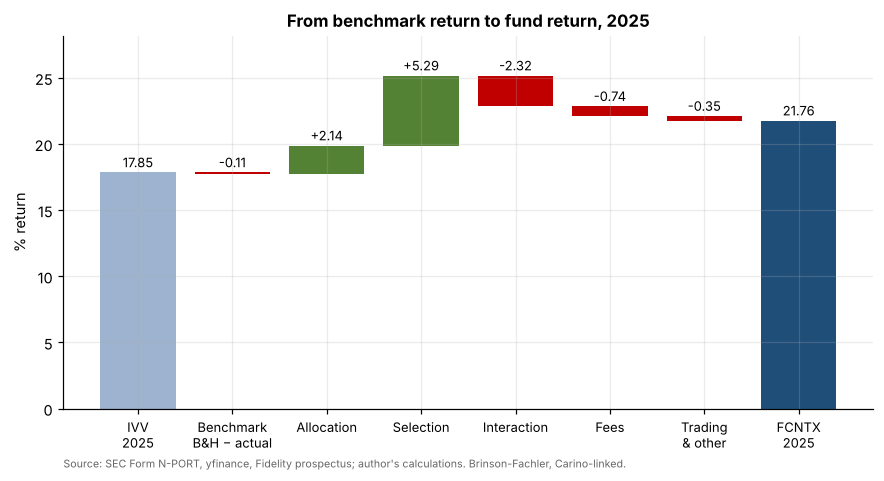

In [9]:
# Waterfall: benchmark -> method gap -> allocation -> selection -> interaction -> fees -> trading -> fund
steps = [("IVV\n2025", Rb_act), ("Benchmark\nB&H − actual", Rb_bh - Rb_act), ("Allocation", TOT["Allocation"]),
         ("Selection", TOT["Selection"]), ("Interaction", TOT["Interaction"]), ("Fees", -FEE_2025),
         ("Trading\n& other", (Rp_act - Rp_bh) + FEE_2025)]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
level = 0.0
for i, (lab, v) in enumerate(steps):
    if i == 0:
        ax.bar(i, v * 100, color="#9DB3CF"); level = v
        ax.text(i, v * 100 + 0.4, f"{v * 100:.2f}", ha="center", fontsize=8.5)
        continue
    bottom = level if v >= 0 else level + v
    ax.bar(i, abs(v) * 100, bottom=bottom * 100, color=PALETTE[2] if v >= 0 else "#C00000")
    level += v
    ax.text(i, (bottom + abs(v)) * 100 + 0.4, f"{v * 100:+.2f}", ha="center", fontsize=8.5)
ax.bar(len(steps), Rp_act * 100, color=PALETTE[0]); ax.text(len(steps), Rp_act * 100 + 0.4, f"{Rp_act * 100:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(len(steps) + 1), [s_[0] for s_ in steps] + ["FCNTX\n2025"], fontsize=8.5)
ax.set_ylim(0, max(Rp_act, Rb_act, Rb_bh + TOT["Allocation"] + TOT["Selection"]) * 100 + 3)
ax.set_ylabel("% return"); ax.set_title("From benchmark return to fund return, 2025")
source(ax, "Source: SEC Form N-PORT, yfinance, Fidelity prospectus; author's calculations. Brinson-Fachler, Carino-linked.")
fig.savefig(FIG / "fig_waterfall.png"); plt.show()

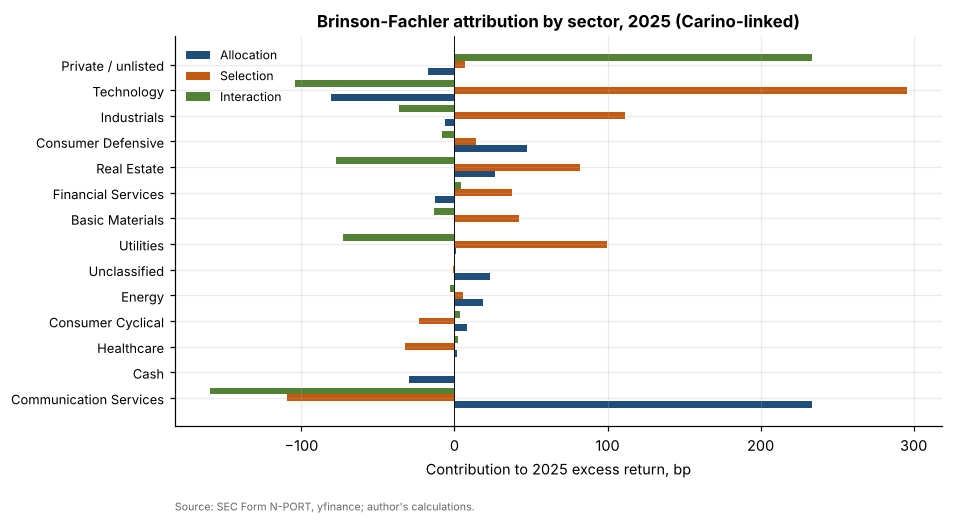

In [10]:
L2 = LINK.copy(); L2["Total"] = L2.sum(axis=1)
L2 = L2.sort_values("Total")
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(L2))
left = np.zeros(len(L2))
for i, c in enumerate(["Allocation", "Selection", "Interaction"]):
    v = L2[c].values * 1e4
    ax.barh(y + (i - 1) * 0.27, v, 0.27, label=c, color=PALETTE[i])
ax.set_yticks(y, L2.index, fontsize=8.5); ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("Contribution to 2025 excess return, bp"); ax.legend(fontsize=8)
ax.set_title("Brinson-Fachler attribution by sector, 2025 (Carino-linked)")
source(ax, "Source: SEC Form N-PORT, yfinance; author's calculations.")
fig.savefig(FIG / "fig_attribution_sector.png"); plt.show()

## Conclusion rule

In [11]:
a6, t6 = REG.loc["FF5 + Mom", "Alpha (ann.)"], REG.loc["FF5 + Mom", "t(alpha)"]
largest = TOT.abs().idxmax()
skill = (a6 > 0 and t6 > 2 and largest == "Selection")
verdict = "skill" if skill else "exposure"
print(f"Six-factor alpha {a6:.2%} (t = {t6:.2f}); largest Brinson effect: {largest} ({TOT[largest]:.2%}) -> {verdict}")

Six-factor alpha 0.73% (t = 0.78); largest Brinson effect: Selection (5.29%) -> exposure


In [12]:
REG.to_csv(DATA / "regressions.csv"); ROLL.to_csv(DATA / "rolling_alpha_beta.csv"); REL.to_csv(DATA / "relative_stats.csv")
COV.to_csv(DATA / "coverage.csv", index=False); QR.to_csv(DATA / "quarterly_returns_bh.csv"); LINK.to_csv(DATA / "brinson_2025_linked.csv")
RES.to_csv(DATA / "residual_2025.csv"); TOP.to_csv(DATA / "top10_contributors.csv"); BOT.to_csv(DATA / "top10_detractors.csv")
json.dump({"alpha6": a6, "t6": t6, "largest_effect": largest, "verdict": verdict, "Rp_bh": Rp_bh, "Rb_bh": Rb_bh,
           "Rp_act": Rp_act, "Rb_act": Rb_act, "effects": TOT.to_dict(), "ivv_alpha6": ivv6.params["const"] * 12,
           "ivv_beta6": ivv6.params["Mkt-RF"], "reg_start": str(ex.index[0].date()), "reg_end": str(ex.index[-1].date()),
           "n_reg": len(ex), "fee_2025": FEE_2025}, open(DATA / "meta.json", "w"), indent=2, default=float)